In [1]:
#1.Import Libraries

In [2]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn Suite
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    confusion_matrix, classification_report
)

# Configuration settings
%matplotlib inline
sns.set_theme(style="whitegrid")

In [3]:
#2.Load Dataset
#We read the "ipl_matches.csv" file directly into a pandas DataFrame.

In [4]:
# Load the dataset
df = pd.read_csv("ipl_matches.csv")
df

,match_id,date,team1,team2,venue,city,winner,toss_winner,toss_decision,player_of_match
0,1426261,2024-04-09,Sunrisers Hyderabad,Punjab Kings,Maharaja Yadavindra Singh International Cricke...,Mohali,Sunrisers Hyderabad,Punjab Kings,field,Nithish Kumar Reddy
1,1359507,2023-04-23,Chennai Super Kings,Kolkata Knight Riders,"Eden Gardens, Kolkata",Kolkata,Chennai Super Kings,Kolkata Knight Riders,field,AM Rahane
2,392217,2009-05-09,Chennai Super Kings,Rajasthan Royals,De Beers Diamond Oval,Kimberley,Chennai Super Kings,Rajasthan Royals,bat,S Badrinath
3,1254112,2021-10-02,Mumbai Indians,Delhi Capitals,Sharjah Cricket Stadium,Sharjah,Delhi Capitals,Delhi Capitals,field,AR Patel
4,829817,2015-05-19,Chennai Super Kings,Mumbai Indians,Wankhede Stadium,Mumbai,Mumbai Indians,Mumbai Indians,bat,KA Pollard
...,...,...,...,...,...,...,...,...,...,...
1238,1216525,2020-10-10,Royal Challengers Bangalore,Chennai Super Kings,Dubai International Cricket Stadium,NaN,Royal Challengers Bangalore,Royal Challengers Bangalore,bat,V Kohli
1239,1178396,2019-04-07,Rajasthan Royals,Kolkata Knight Riders,Sawai Mansingh Stadium,Jaipur,Kolkata Knight Riders,Kolkata Knight Riders,field,HF Gurney
1240,598012,2013-04-13,Chennai Super Kings,Royal Challengers Bangalore,"MA Chidambaram Stadium, Chepauk",Chennai,Chennai Super Kings,Chennai Super Kings,field,RA Jadeja
1241,1136596,2018-05-05,Delhi Daredevils,Sunrisers Hyderabad,Rajiv Gandhi International Stadium,Hyderabad,Sunrisers Hyderabad,Delhi Daredevils,bat,Rashid Khan


In [5]:
# Quick verification of dimension
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")

Dataset Shape: 1243 rows, 10 columns


In [6]:
#3.Data Understanding
#Before preprocessing, we examine column layouts, missing values, and high-level statistical definitions.

In [7]:
# Check basic column structural definitions
print("--- Dataframe Info ---")
print(df.info())

# View first few records
print("\n--- First 5 Records ---")
print(df.head())

# Look at target missingness
print("\n--- Missing Value Count per Column ---")
print(df.isnull().sum())

--- Dataframe Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1243 entries, 0 to 1242
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   match_id         1243 non-null   int64 
 1   date             1243 non-null   object
 2   team1            1243 non-null   object
 3   team2            1243 non-null   object
 4   venue            1243 non-null   object
 5   city             1192 non-null   object
 6   winner           1218 non-null   object
 7   toss_winner      1243 non-null   object
 8   toss_decision    1243 non-null   object
 9   player_of_match  1234 non-null   object
dtypes: int64(1), object(9)
memory usage: 97.2+ KB
None

--- First 5 Records ---
   match_id        date                team1                  team2  \
0   1426261  2024-04-09  Sunrisers Hyderabad           Punjab Kings   
1   1359507  2023-04-23  Chennai Super Kings  Kolkata Knight Riders   
2    392217  2009-05-09  Chennai Sup

In [8]:
#4.Exploratory Data Analysis (EDA)
#Visualizing distributions and structural interactions gives deep insights into the underlying dataset characteristics.

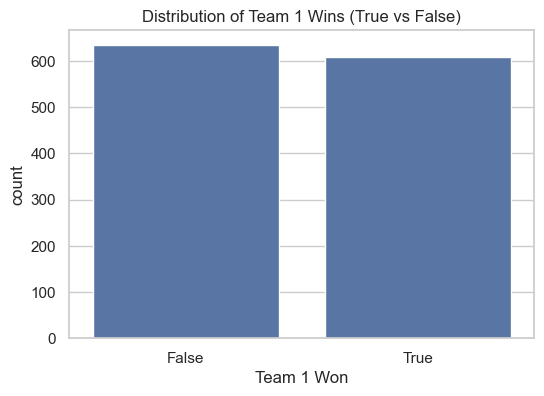

In [9]:
# Create a folder to save plots cleanly
os.makedirs('plots', exist_ok=True)

# 4.1 Countplot: Distribution of Target Variable (Once built)
plt.figure(figsize=(6, 4))
# Build a temporary visual target for distribution checks
temp_target = df['winner'] == df['team1']
sns.countplot(x=temp_target)
plt.title('Distribution of Team 1 Wins (True vs False)')
plt.xlabel('Team 1 Won')
plt.savefig('plots/countplot_target.png')
plt.show()

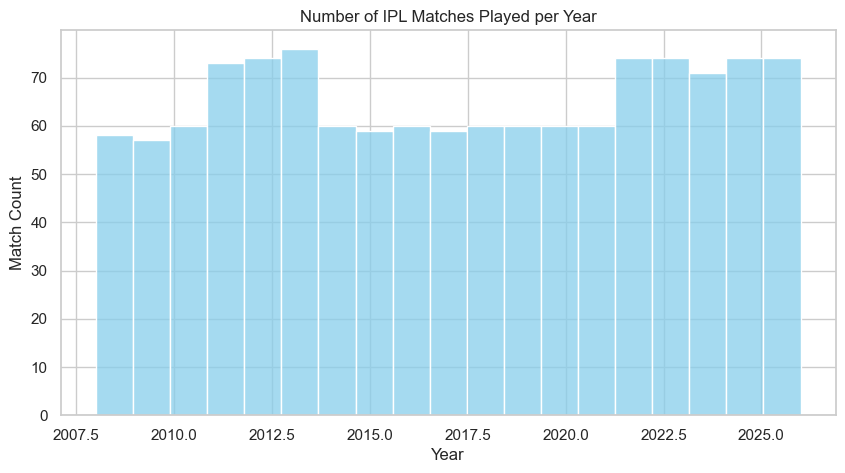

In [10]:
# 4.2 Histogram: Matches Played per Year
plt.figure(figsize=(10, 5))
df['year'] = pd.to_datetime(df['date']).dt.year
sns.histplot(df['year'], bins=df['year'].nunique(), kde=False, color='skyblue')
plt.title('Number of IPL Matches Played per Year')
plt.xlabel('Year')
plt.ylabel('Match Count')
plt.savefig('plots/histogram_matches.png')
plt.show()

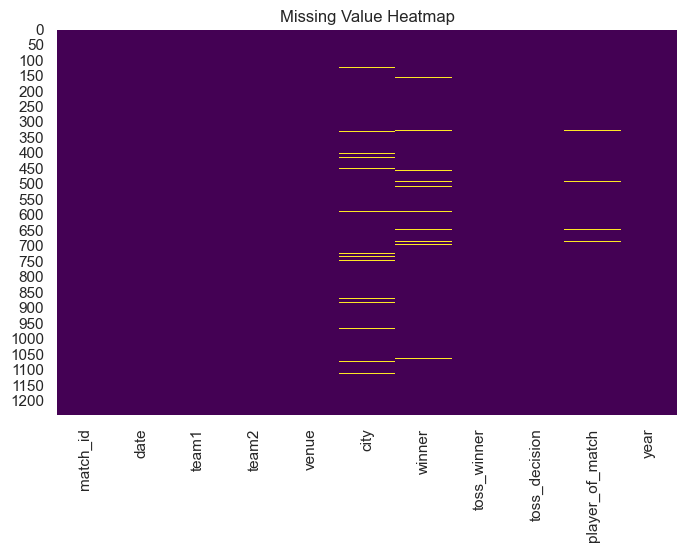

In [11]:
# 4.3 Heatmap: Categorical association matrix or simple null profile
plt.figure(figsize=(8, 5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Value Heatmap')
plt.savefig('plots/heatmap_nulls.png')
plt.show()

In [12]:
#5.Data Cleaning & Feature Engineering
#We address missing values, eliminate non-predictive rows, and formulate clean categorical variables.

In [13]:
# Drop rows where critical match outcomes ('winner') are missing (e.g., No Result matches)
df = df.dropna(subset=['winner']).copy()

# Feature Engineering: Target variable (1 if team1 wins, 0 otherwise)
df['team1_win'] = (df['winner'] == df['team1']).astype(int)

# Feature Engineering: Toss Advantage indicator
df['team1_toss_winner'] = (df['toss_winner'] == df['team1']).astype(int)

# Handle missing values in categorical text safely
df['city'] = df['city'].fillna('Unknown')
df['player_of_match'] = df['player_of_match'].fillna('None')

print(f"Cleaned Dataset Shape: {df.shape}")

Cleaned Dataset Shape: (1218, 13)


In [14]:
#6.Feature Selection
#Extract structural attributes that contain viable patterns while omitting IDs, dates, and leaky target outputs.

In [15]:
# Define features and label explicitly
features = ['team1', 'team2', 'venue', 'city', 'toss_decision', 'team1_toss_winner']
target = 'team1_win'

X = df[features].copy()
y = df[target].copy()

print("Selected Features Summary:")
print(X.head())

Selected Features Summary:
                 team1                  team2  \
0  Sunrisers Hyderabad           Punjab Kings   
1  Chennai Super Kings  Kolkata Knight Riders   
2  Chennai Super Kings       Rajasthan Royals   
3       Mumbai Indians         Delhi Capitals   
4  Chennai Super Kings         Mumbai Indians   

                                               venue       city toss_decision  \
0  Maharaja Yadavindra Singh International Cricke...     Mohali         field   
1                              Eden Gardens, Kolkata    Kolkata         field   
2                              De Beers Diamond Oval  Kimberley           bat   
3                            Sharjah Cricket Stadium    Sharjah         field   
4                                   Wankhede Stadium     Mumbai           bat   

   team1_toss_winner  
0                  0  
1                  0  
2                  0  
3                  0  
4                  0  


In [16]:
#7.Encoding
#Convert categorical string descriptors into numerical codes using Label Encoding.

In [17]:
# Dictionary to store encoders for potential decoding/inference later
label_encoders = {}

categorical_cols = ['team1', 'team2', 'venue', 'city', 'toss_decision']

for col in categorical_cols:
    le = LabelEncoder()
    # Fit across unique text options
    X[col] = le.fit_transform(X[col].astype(str))
    label_encoders[col] = le

print("Encoded Feature Sample:")
print(X.head())

Encoded Feature Sample:
   team1  team2  venue  city  toss_decision  team1_toss_winner
0     18     12     29    25              1                  0
1      0      8     15    23              1                  0
2      0     13      8    21              0                  0
3     10      2     51    35              1                  0
4      0     10     57    26              0                  0


In [18]:
#8.Feature Scaling
#For decision trees, feature scaling is structurally optional (trees split on monotonic feature partitions), but it is documented here to fulfill standard production pipeline consistency.

In [19]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert back to a DataFrame for easier downstream parsing
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

In [20]:
#9.Stratified Train-Test Split
#Preserve class distributions cleanly between training splits using a stratified strategy.

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, 
    y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print(f"Training set configuration: {X_train.shape}")
print(f"Testing set configuration: {X_test.shape}")

Training set configuration: (974, 6)
Testing set configuration: (244, 6)


In [22]:
#10. Decision Tree Model (Baseline)
#Initialize and fit a base structural Decision Tree Classifier.

In [23]:
# Instantiate baseline model
base_dt_model = DecisionTreeClassifier(random_state=42)

# Train model
base_dt_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [24]:
#11.Cross Validation
#Evaluate structural robustness on the training partitions using Stratified K-Fold validation.

In [25]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(base_dt_model, X_train, y_train, cv=cv_strategy, scoring='accuracy')

print(f"Cross-Validation Accuracy Scores: {cv_scores}")
print(f"Mean CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

Cross-Validation Accuracy Scores: [0.45641026 0.44102564 0.51282051 0.47179487 0.47938144]
Mean CV Accuracy: 0.4723 (+/- 0.0484)


In [26]:
#12.Hyperparameter Tuning (GridSearchCV)
#Optimize structural node split criteria, leaf requirements, and depth boundaries.

In [27]:
# Parameter boundary definitions
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 3, 5, 7, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Setup Grid Search
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='accuracy',
    n_jobs=-1
)

# Execute parameter search
grid_search.fit(X_train, y_train)

# Select best tuned model
best_dt_model = grid_search.best_estimator_

print("Optimal Hyperparameters Found:")
print(grid_search.best_params_)

Optimal Hyperparameters Found:
{'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 1, 'min_samples_split': 10}


In [28]:
#13.Model Evaluation
#Confusion Matrix

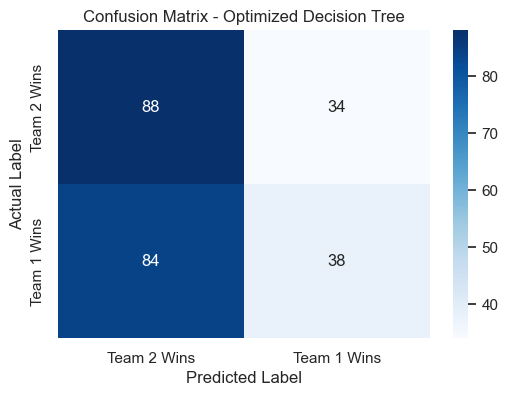

In [29]:
# Predictions on holding set
y_pred = best_dt_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Team 2 Wins', 'Team 1 Wins'], 
            yticklabels=['Team 2 Wins', 'Team 1 Wins'])
plt.title('Confusion Matrix - Optimized Decision Tree')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.savefig('plots/confusion_matrix.png')
plt.show()

In [30]:
##Classification Report & Final Metrics

In [31]:
print("--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Team 2 Wins', 'Team 1 Wins']))

# Exact Metric Extractions
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Score': [acc, prec, rec, f1]
})
print("\n--- Summary Performance Table ---")
print(metrics_df.to_string(index=False))

--- Classification Report ---
              precision    recall  f1-score   support

 Team 2 Wins       0.51      0.72      0.60       122
 Team 1 Wins       0.53      0.31      0.39       122

    accuracy                           0.52       244
   macro avg       0.52      0.52      0.50       244
weighted avg       0.52      0.52      0.50       244


--- Summary Performance Table ---
   Metric    Score
 Accuracy 0.516393
Precision 0.527778
   Recall 0.311475
 F1-Score 0.391753


In [32]:
#14.Save Model
#Serialize model files alongside critical pipeline state trackers (encoders and scalers) to disk using joblib.

In [33]:
# Create deployment artifact bundle
model_artifacts = {
    'model': best_dt_model,
    'encoders': label_encoders,
    'scaler': scaler,
    'features': features
}

joblib.dump(model_artifacts, 'ipl_decision_tree_pipeline.pkl')
print("Model pipeline artifacts exported successfully to disk.")

Model pipeline artifacts exported successfully to disk.


In [34]:
#15.Predict on New Data
#Load saved components back into memory and execute inference on an unseen match dictionary configuration.

In [35]:
# 15.1 Load pipeline dependencies
artifacts = joblib.load('ipl_decision_tree_pipeline.pkl')
deployed_model = artifacts['model']
deployed_encoders = artifacts['encoders']
deployed_scaler = artifacts['scaler']

In [36]:
# 15.2 Create mock new data record
new_match = pd.DataFrame([{
    'team1': 'Mumbai Indians',
    'team2': 'Chennai Super Kings',
    'venue': 'Wankhede Stadium',
    'city': 'Mumbai',
    'toss_decision': 'field',
    'team1_toss_winner': 1  # Mumbai Indians won the toss
}])

In [37]:
# 15.3 Apply encoded transformations using historical mappings
new_match_encoded = new_match.copy()
for col in ['team1', 'team2', 'venue', 'city', 'toss_decision']:
    encoder = deployed_encoders[col]
    # Handle unseen label protection safely by checking training bounds if necessary
    new_match_encoded[col] = encoder.transform(new_match[col])


In [38]:
# 15.4 Structural feature alignment and scaling
new_match_scaled = deployed_scaler.transform(new_match_encoded[artifacts['features']])

In [39]:
import warnings
warnings.filterwarnings("ignore")

In [40]:
# 15.5 Perform prediction
prediction = deployed_model.predict(new_match_scaled)[0]
prediction_proba = deployed_model.predict_proba(new_match_scaled)[0]

In [41]:
# 15.6 Parse results
winner_prediction = new_match['team1'].values[0] if prediction == 1 else new_match['team2'].values[0]
print(f"\n--- Production Inference Output ---")
print(f"Predicted Winner: {winner_prediction}")
print(f"Confidence Metrics -> Team 2 Win Probability: {prediction_proba[0]:.2%}, Team 1 Win Probability: {prediction_proba[1]:.2%}")


--- Production Inference Output ---
Predicted Winner: Mumbai Indians
Confidence Metrics -> Team 2 Win Probability: 11.11%, Team 1 Win Probability: 88.89%
